## porespy + phbin

### persistent homology analysis

(c)pearcandy

In [1]:
import porespy as ps
import matplotlib.pyplot as plt
import numpy as np
import phbin, cv2
import scipy
from IPython.display import display, Image
%matplotlib notebook

In [2]:
!ls ./sem_binary

entry18.jpg  entry20.jpg  entry22.jpg  entry3.jpg  fb3sdx.jpg  rd8.jpg
entry19.jpg  entry21.jpg  entry23.jpg  fb1sdx.jpg  fb940.jpg


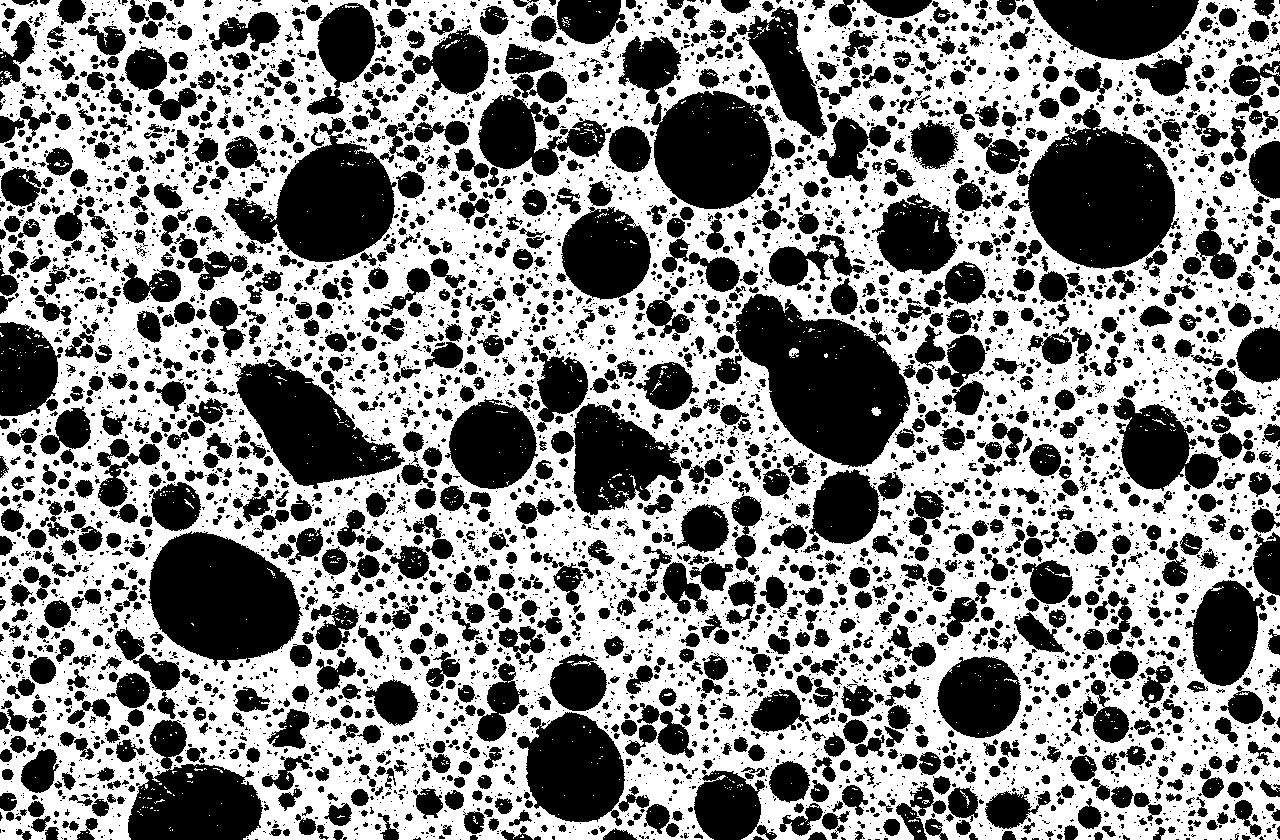

In [6]:
#sem0 = ps.generators.polydisperse_spheres([300,300],0.4,scipy.stats.norm(loc=10,scale=5))
#plt.imsave('./sem0',sem0,cmap='gray')
filename='entry18'
display(Image('./sem_binary/'+filename+'.jpg'))

In [7]:
img, sem_bin = phbin.make_input_imgobj('./sem_binary/'+filename+'.jpg')

<IPython.core.display.Javascript object>


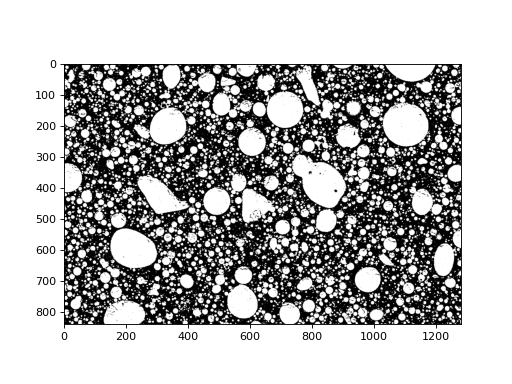

In [8]:
plt.close()
plt.imshow(sem_bin,cmap='gray')

## persistent homology

In [9]:
pds = phbin.make_pd([sem_bin],mode='sublevel',dim=0)

100%|██████████| 1/1 [00:01<00:00,  1.77s/it]


<IPython.core.display.Javascript object>


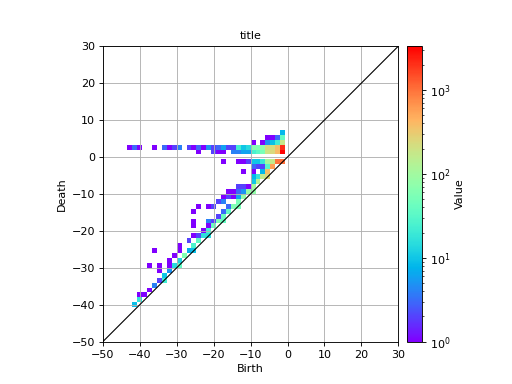

In [10]:
plt.close()
phbin.draw_pd(pds[0],x_range=[-50,30],x_bins=60)

<IPython.core.display.Javascript object>


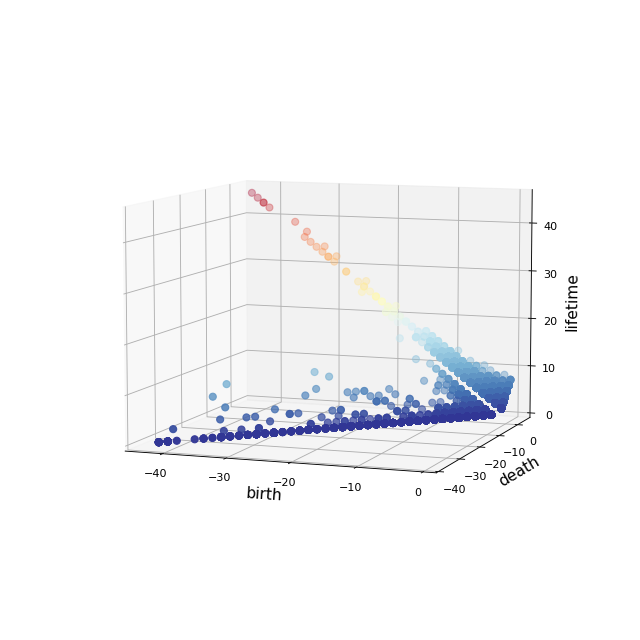

In [13]:
phbin.draw_pd_lifetime(pds[0])

In [142]:
pimage = phbin.make_pi(pds,mesh_range=(-40,20),bins=60,sigma=0.5,weight=('atan',0.0001,1),superlevel=False)

100%|██████████| 1/1 [00:00<00:00, 386.68it/s]


In [141]:
pi = np.array(pimage['pi'][0])
mesh = pimage['mesh']

<IPython.core.display.Javascript object>


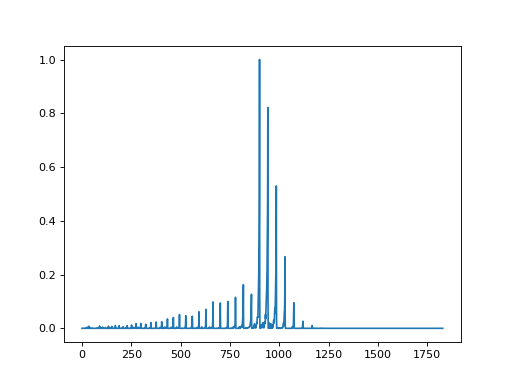

In [41]:
plt.close()
plt.close()
plt.plot(pi)

<IPython.core.display.Javascript object>


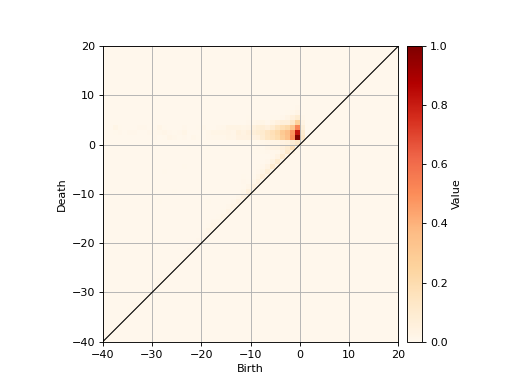

In [42]:
phbin.draw_pi(pi,mesh)

## Reverse Map

In [12]:
phtrees = phbin.make_phtrees([sem_bin],mode='sublevel',dim=0)

100%|██████████| 1/1 [00:32<00:00, 32.04s/it]


In [44]:
area = mesh.mask_from_vector(pi>0.2)

<IPython.core.display.Javascript object>


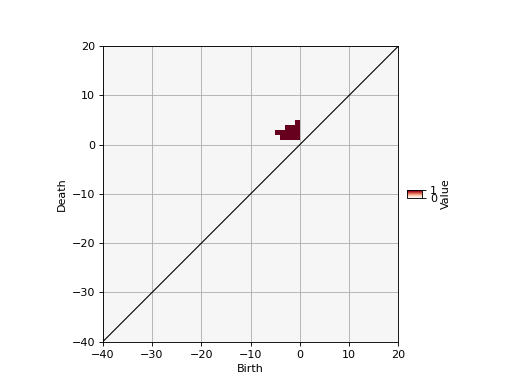

In [45]:
area.plot(colorbar={"type":"linear-midpoint","midpoint":0.0})

In [46]:
nodes = phbin.pd_filter(pds[0],phtrees[0],area)

In [47]:
phbin.reverse_map(nodes,img)

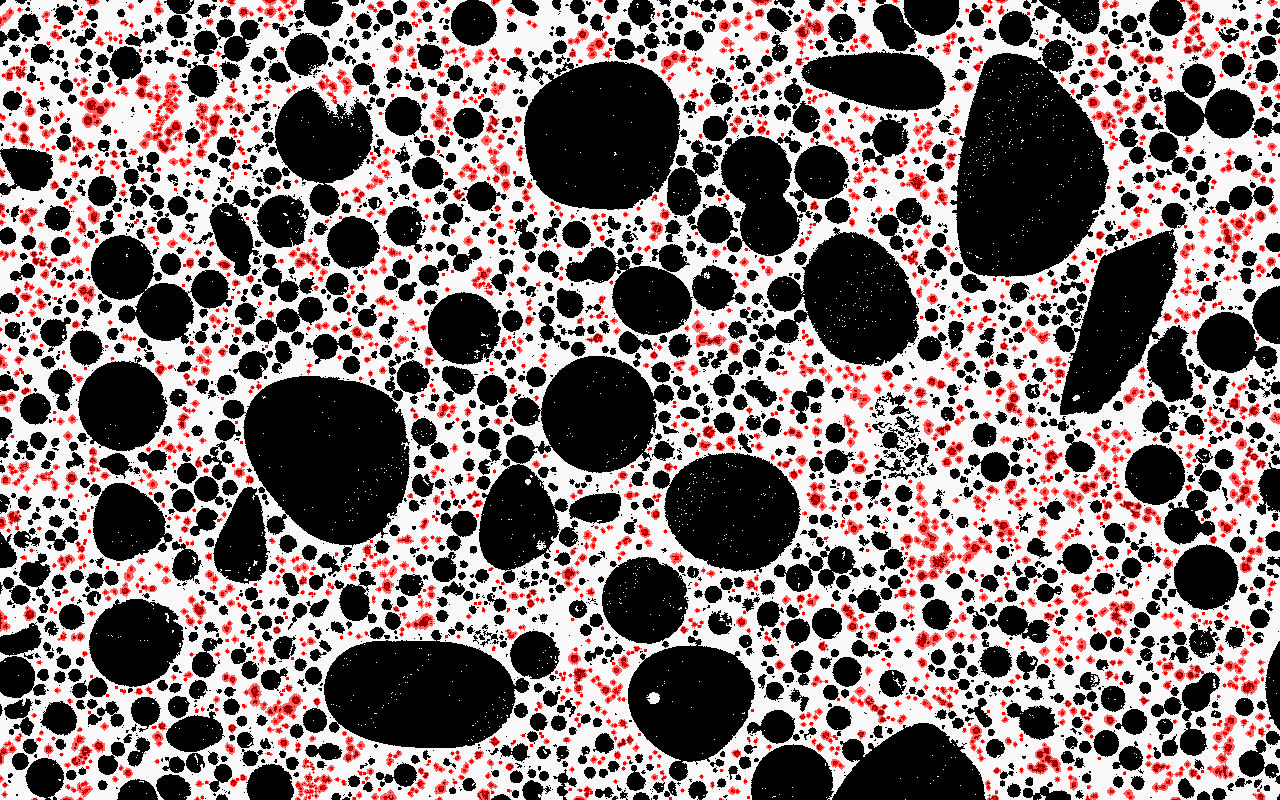

In [48]:
display(Image('./reverse.png'))

## Reverse Map (life time)

In [12]:
nodes = phbin.pd_liftime_filter(pds[0],phtrees[0],th=40)

In [13]:
phbin.reverse_map(nodes,img)

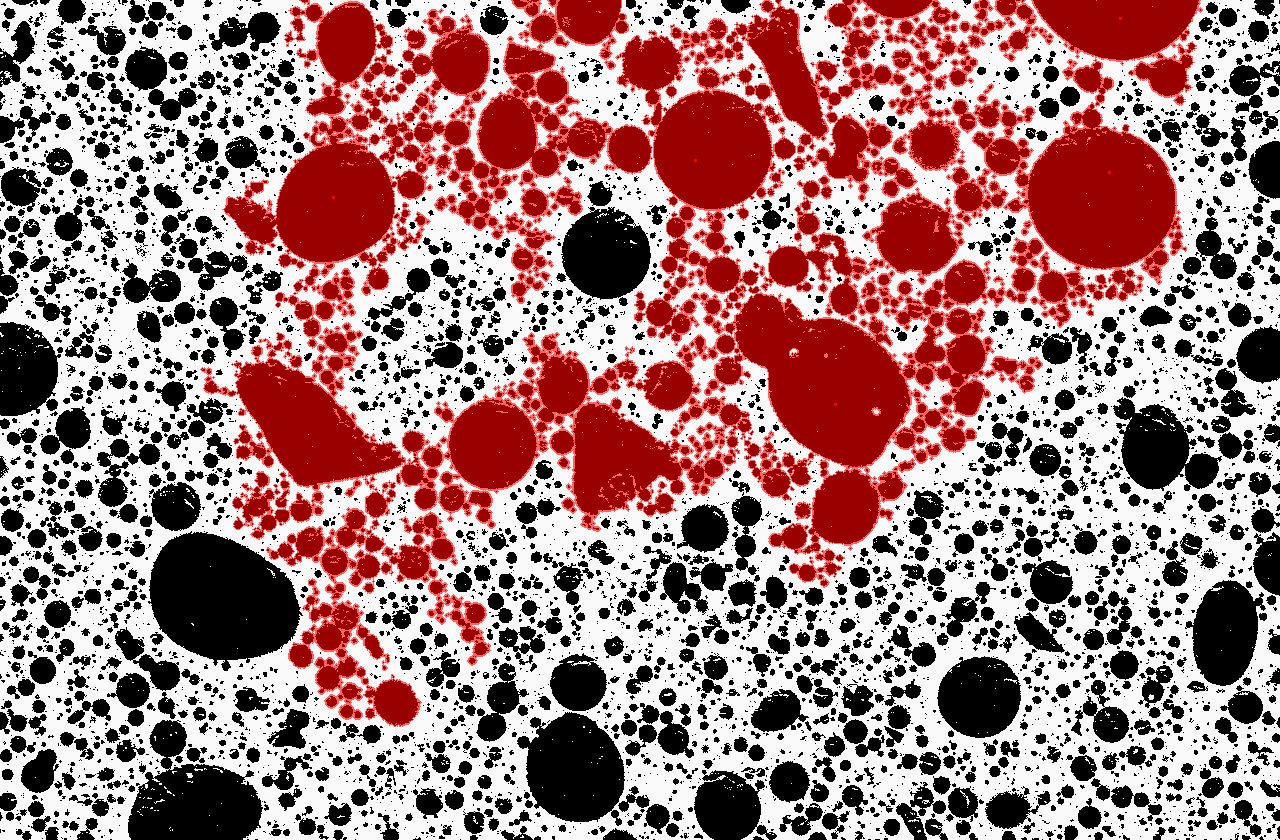

In [14]:
display(Image('./reverse.png'))

In [32]:
nodes =phtrees[0].pair_nodes_in_rectangle(-30,-20,-20,0) #xmin, xmax, ymin, ymax

In [33]:
phbin.reverse_map(nodes,img)

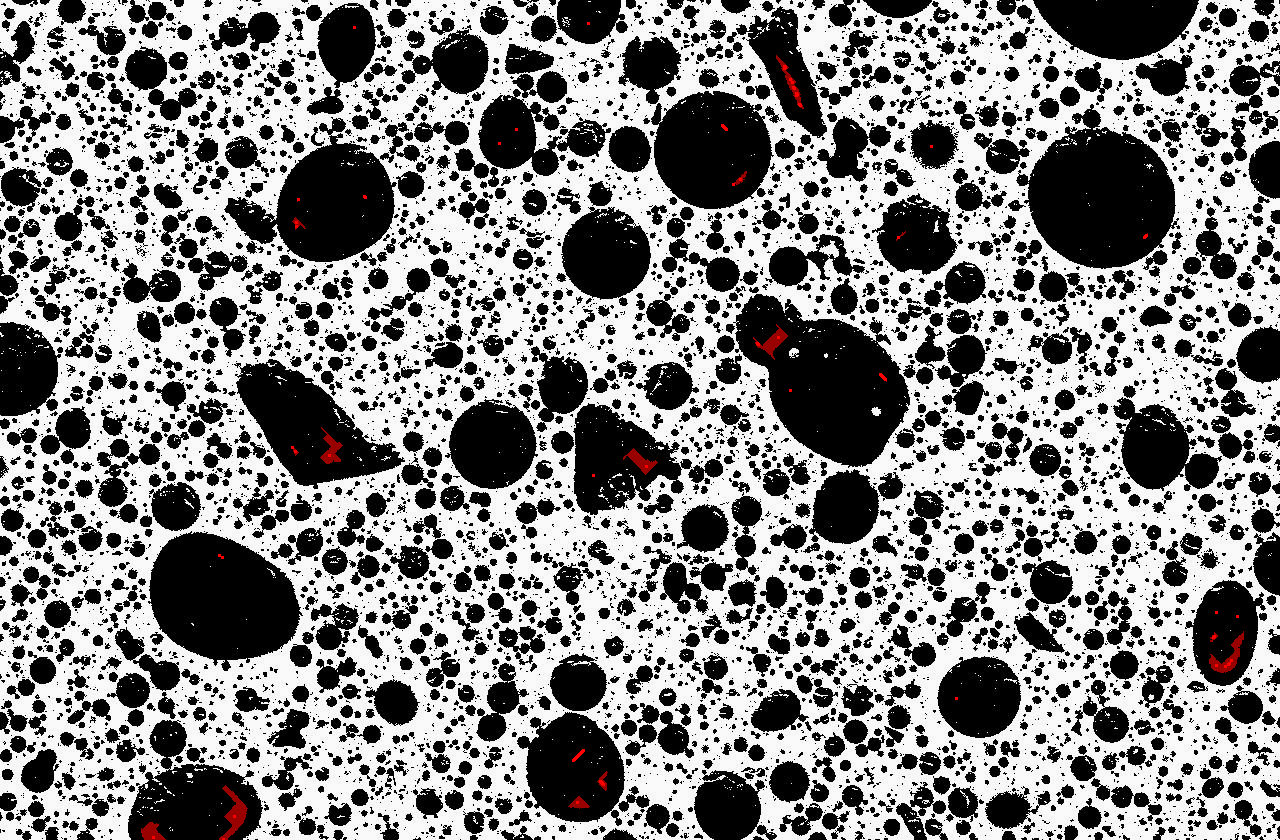

In [34]:
display(Image('./reverse.png'))